In [40]:
import torch

In [41]:
import numpy as np
import matplotlib.pyplot as plt
import torch.nn as nn
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score


In [42]:
SEED =42
np.random.seed(SEED)
torch.manual_seed(SEED)

In [43]:
device = "cuda" if torch.cuda.is_available() else "cpu"

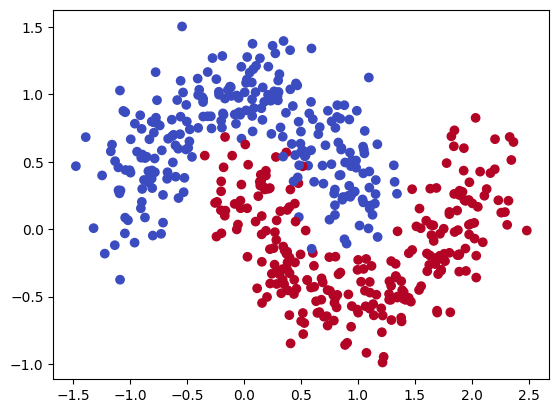

In [44]:
X,y = make_moons(n_samples=500,noise=0.2,random_state=SEED)
Y=y.reshape(500,1)

plt.scatter(X[:,0],X[:,1],c=Y,cmap='coolwarm')
plt.show()

In [45]:
X_temp,X_test,Y_temp,Y_test = train_test_split(X,Y,test_size=0.2,random_state=SEED)

In [46]:
X_train,X_val,Y_train,Y_val=train_test_split(X_temp,Y_temp,test_size=0.125,random_state=SEED)

In [47]:
print(device)

cpu


In [48]:
#numpy yo tensors

def to_t(a):
  return torch.tensor(a,dtype=torch.float32,device=device)

X_train_t, Y_train_t = to_t(X_train), to_t(Y_train)
X_val_t, Y_val_t = to_t(X_val), to_t(Y_val)
X_test_t, Y_test_t = to_t(X_test), to_t(Y_test)



In [49]:
#defining the model
class Net(nn.Module):
  def __init__(self):
    super().__init__()
    self.fc1 = nn.Linear(2,4)
    self.fc2 = nn.Linear(4,4)
    self.fc3 = nn.Linear(4,1)

  def forward(self,x):
    x = torch.sigmoid(self.fc1(x)) #output of the first layer
    x = torch.sigmoid(self.fc2(x)) #output of the second layer
    x = torch.sigmoid(self.fc3(x)) #output of the third layer
    return(x)




In [50]:
model = Net().to(device)
print(model)

Net(
  (fc1): Linear(in_features=2, out_features=4, bias=True)
  (fc2): Linear(in_features=4, out_features=4, bias=True)
  (fc3): Linear(in_features=4, out_features=1, bias=True)
)


In [55]:
#loss and optimizer
#BCE and SGD

criterion = nn.BCELoss()
optimizer = torch.optim.SGD(model.parameters(),lr=0.1)



In [59]:
#training loop

epochs =2000
train_loss,val_losses =[],[]

for epoch in range(epochs):

  model.train()

  optimizer.zero_grad()
  Y_pred = model(X_train_t)
  loss = criterion(Y_pred,Y_train_t)
  loss.backward()
  optimizer.step()
  train_loss.append(loss.item())

  model.eval()
  with torch.no_grad():
    val_loss = criterion(model(X_val_t),Y_val_t)
    val_losses.append(val_loss.item())

  if (epoch+1)%200 ==0:
    print(f"epoch{epoch+1:4d} | train loss{loss.item():.4f} val loss{val_loss.item():.4f}")

epoch 200 | train loss0.3145 val loss0.1696
epoch 400 | train loss0.3134 val loss0.1671
epoch 600 | train loss0.3127 val loss0.1655
epoch 800 | train loss0.3120 val loss0.1644
epoch1000 | train loss0.3115 val loss0.1636
epoch1200 | train loss0.3109 val loss0.1630
epoch1400 | train loss0.3104 val loss0.1625
epoch1600 | train loss0.3100 val loss0.1620
epoch1800 | train loss0.3095 val loss0.1616
epoch2000 | train loss0.3091 val loss0.1613


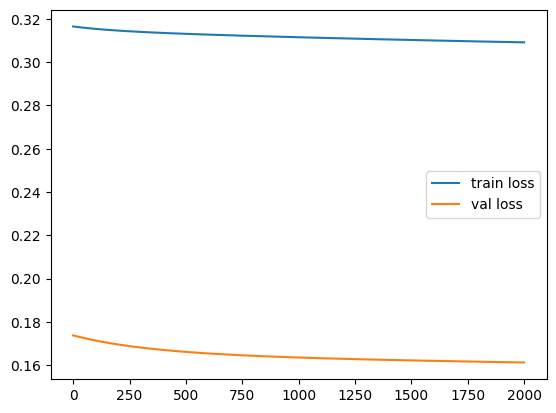

In [60]:
plt.plot(train_loss,label='train loss')
plt.plot(val_losses,label='val loss')
plt.legend()
plt.show()

In [58]:
model.eval()

with torch.no_grad():
  for name, Xs, Ys in[
      ("Train",X_train_t,Y_train_t),
      ("Val",X_val_t,Y_val_t),
      ("Test",X_test_t,Y_test_t)]:
      preds =(model(Xs)>0.5).float()
      acc = (preds ==Ys).float().mean()*100
      print(f"{name} accuracy: {acc:.2f}")


Train accuracy: 84.00
Val accuracy: 94.00
Test accuracy: 85.00


In [ ]:
#Drawing the decision boundary

